В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 5

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['XMR', 'XRP', 'XLM', 'SOL', 'ADA', 'BTC', 'DOT', 'ETH', 'LINK', 'DOGE']

In [6]:
# strategy={"extra_buy_amount": 500}
strategy={}

04:02:16 - cmdstanpy - INFO - Chain [1] start processing
04:02:16 - cmdstanpy - INFO - Chain [1] done processing


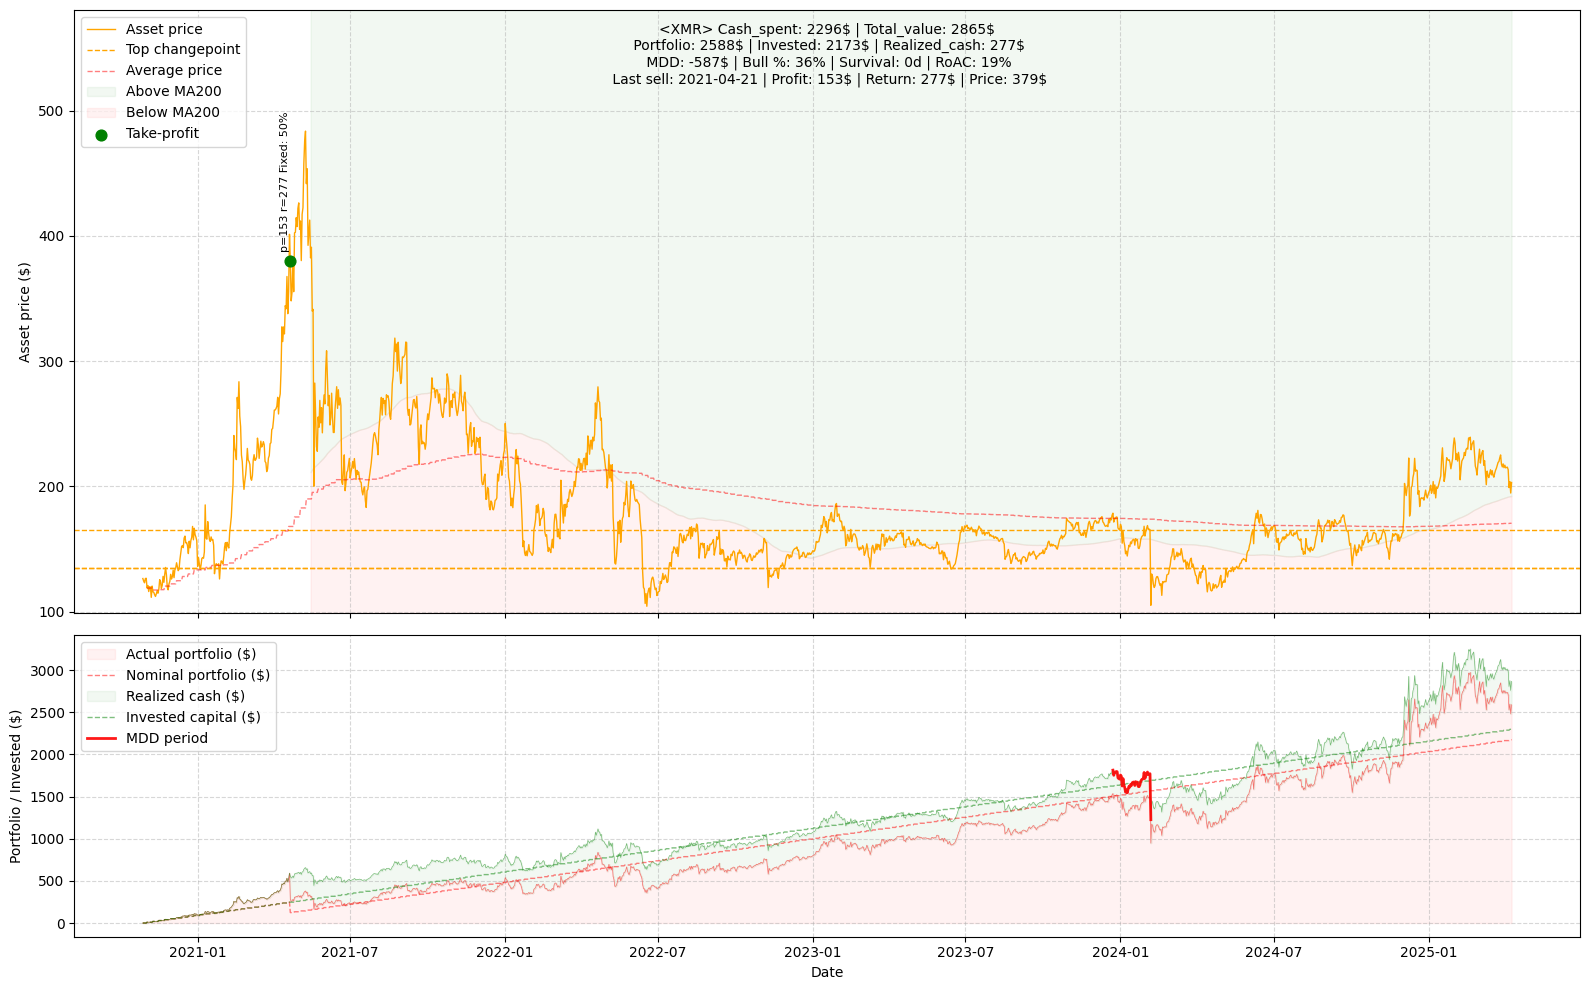

04:02:16 - cmdstanpy - INFO - Chain [1] start processing
04:02:17 - cmdstanpy - INFO - Chain [1] done processing


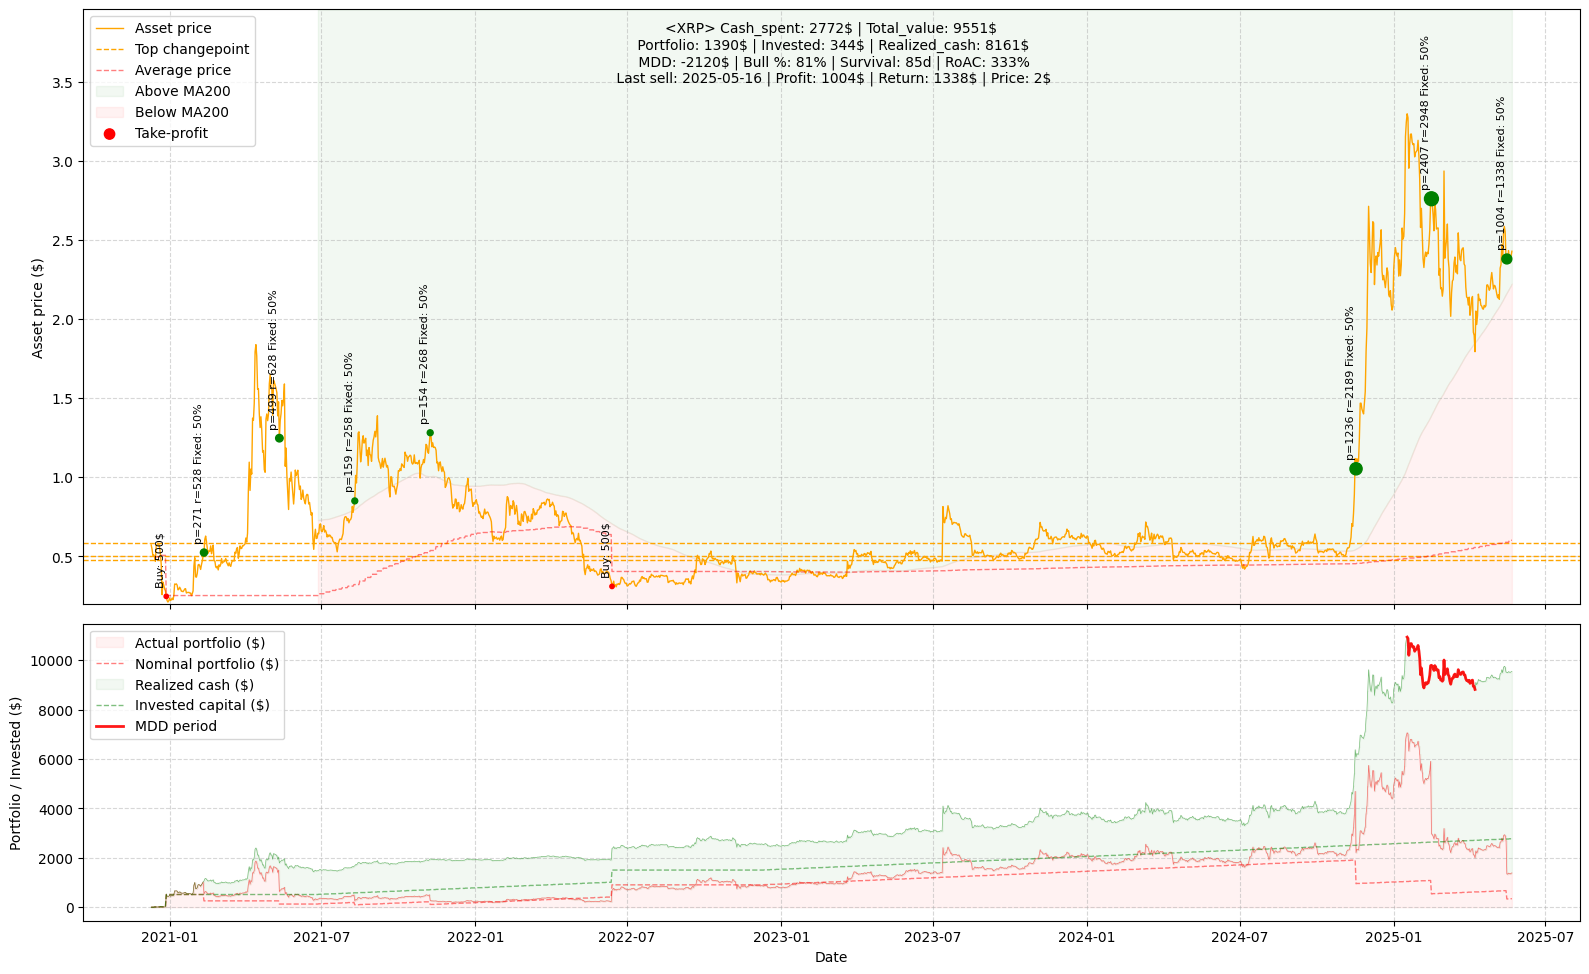

04:02:17 - cmdstanpy - INFO - Chain [1] start processing
04:02:17 - cmdstanpy - INFO - Chain [1] done processing


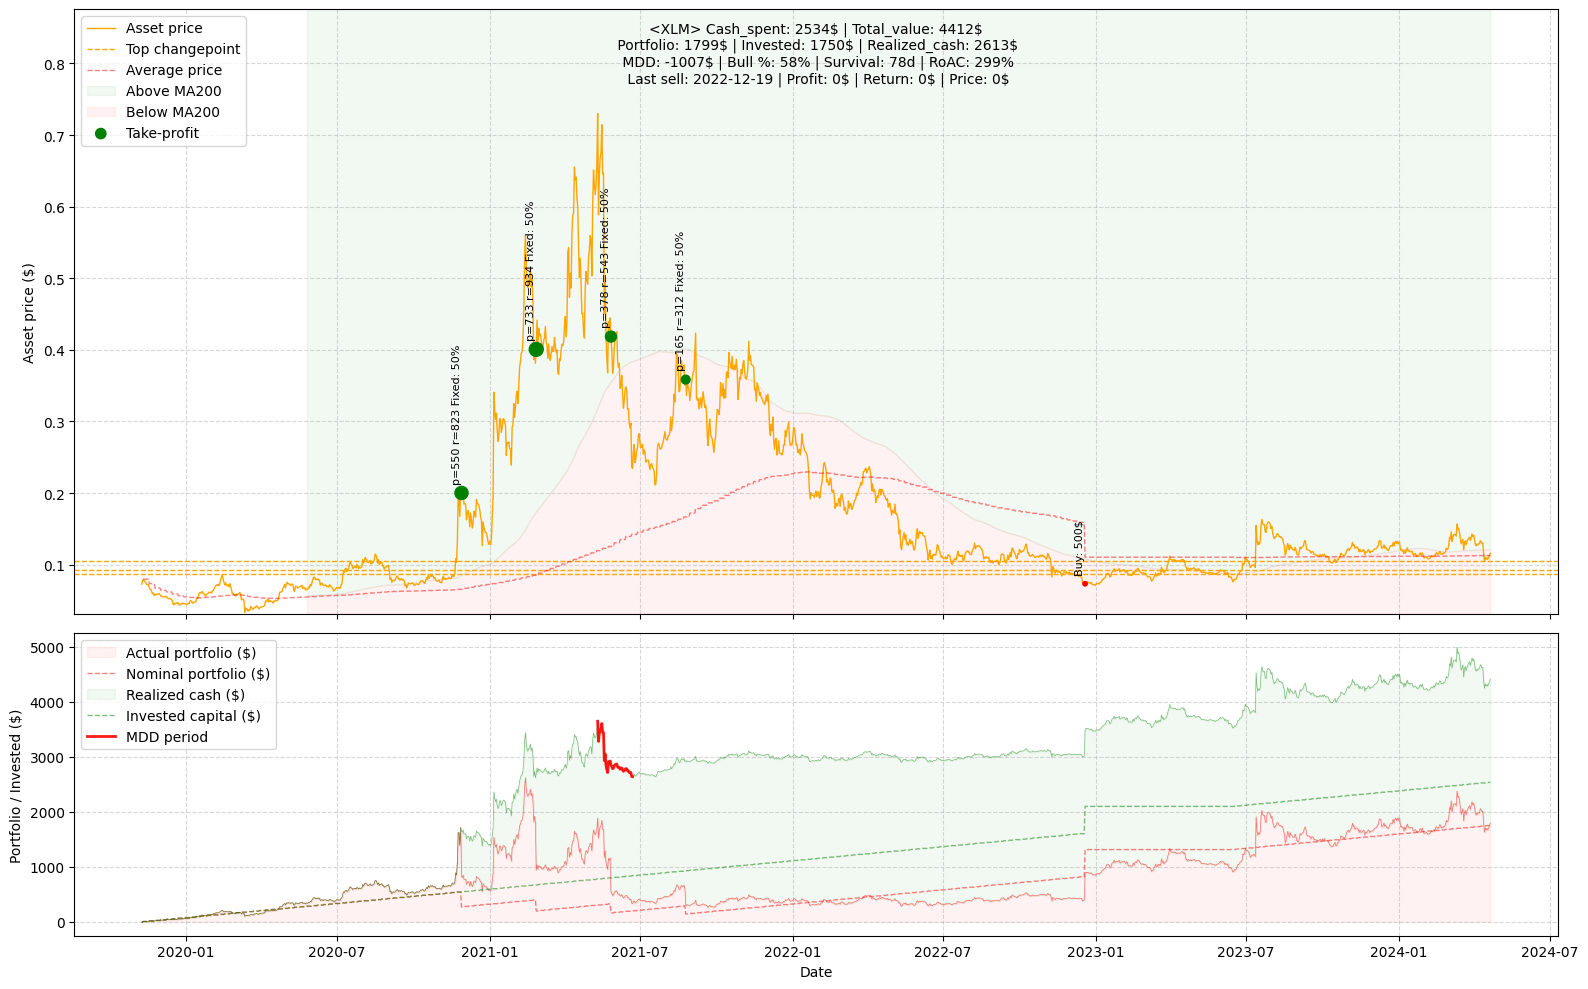

04:02:18 - cmdstanpy - INFO - Chain [1] start processing
04:02:18 - cmdstanpy - INFO - Chain [1] done processing


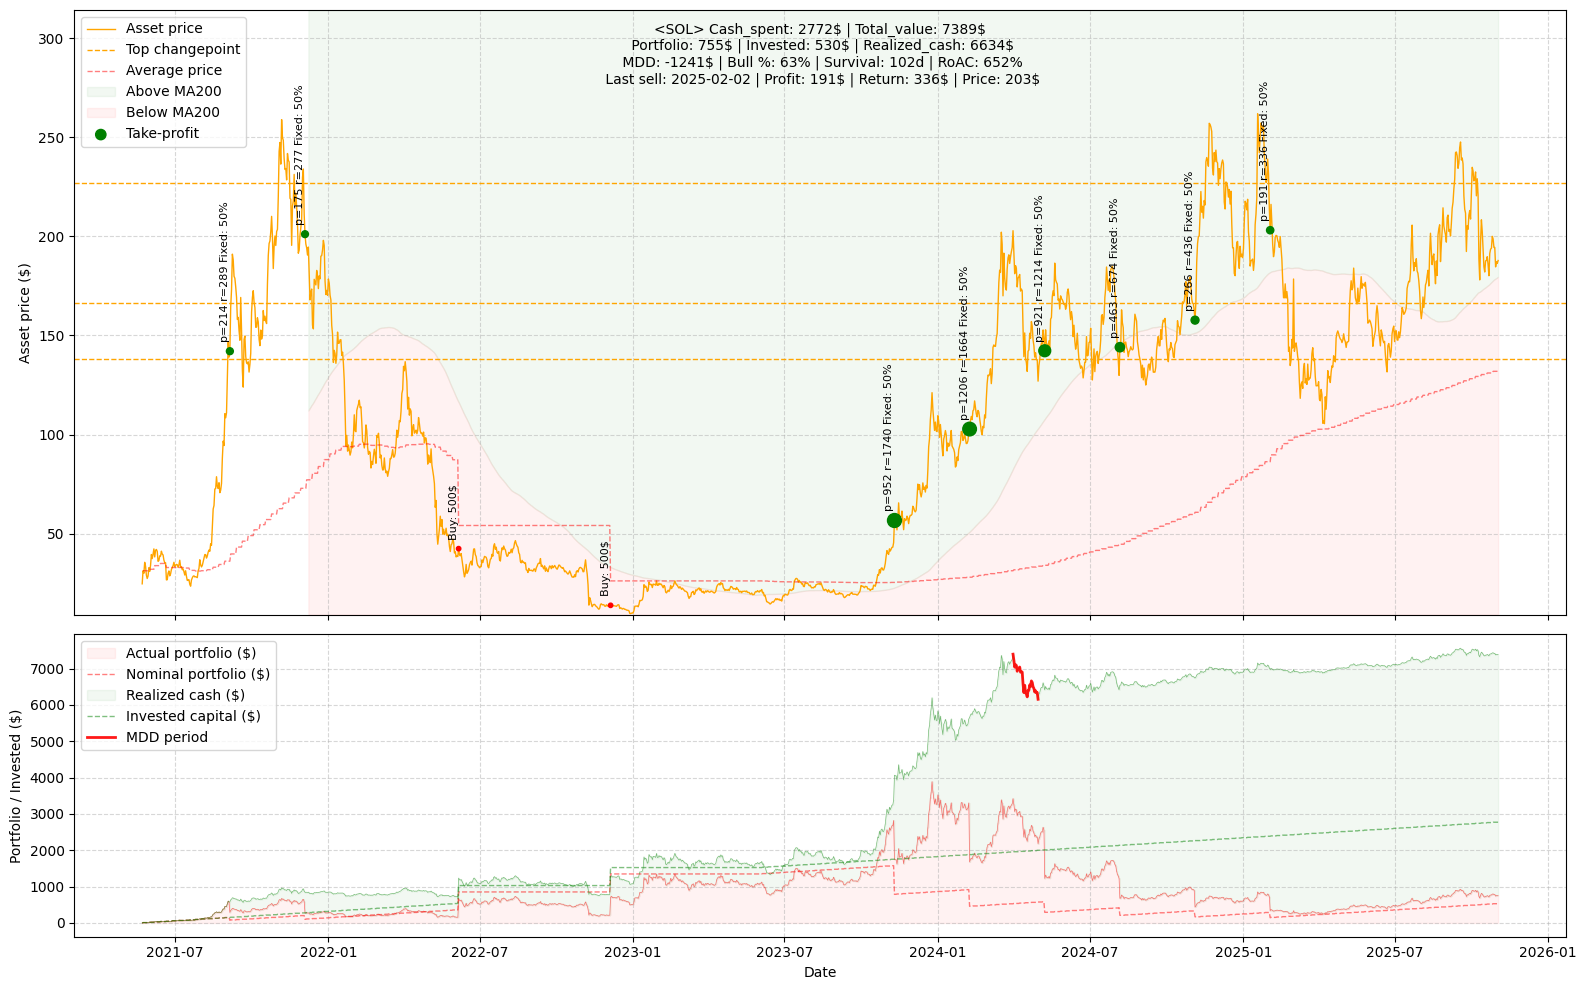

04:02:18 - cmdstanpy - INFO - Chain [1] start processing
04:02:19 - cmdstanpy - INFO - Chain [1] done processing


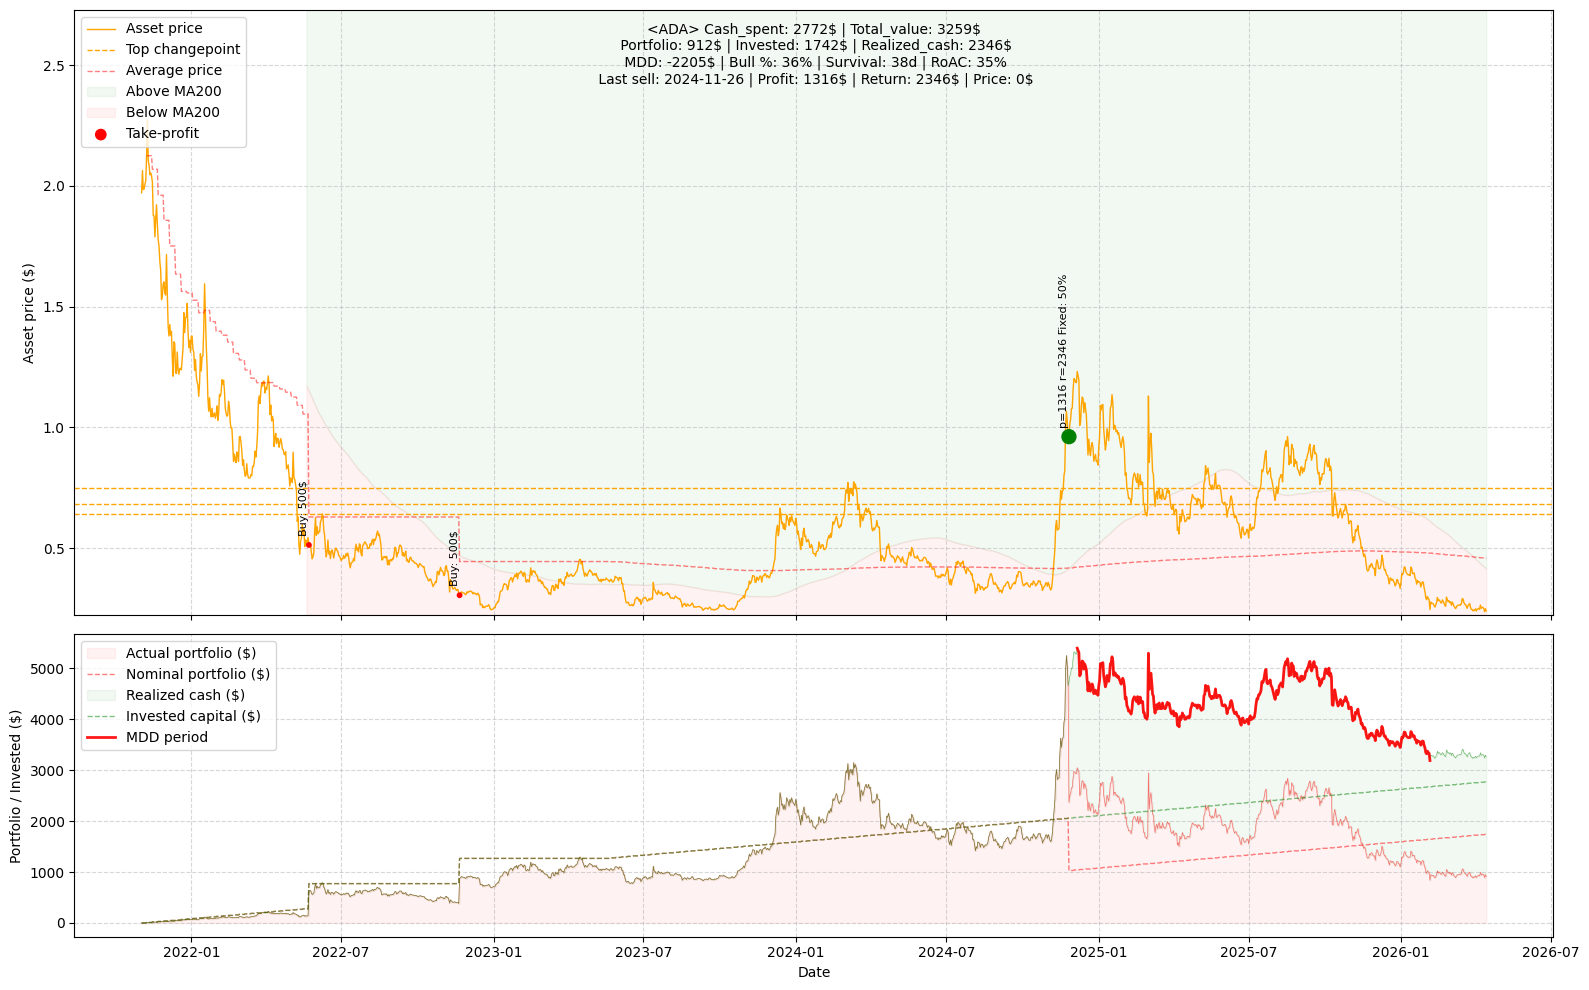

04:02:19 - cmdstanpy - INFO - Chain [1] start processing
04:02:19 - cmdstanpy - INFO - Chain [1] done processing


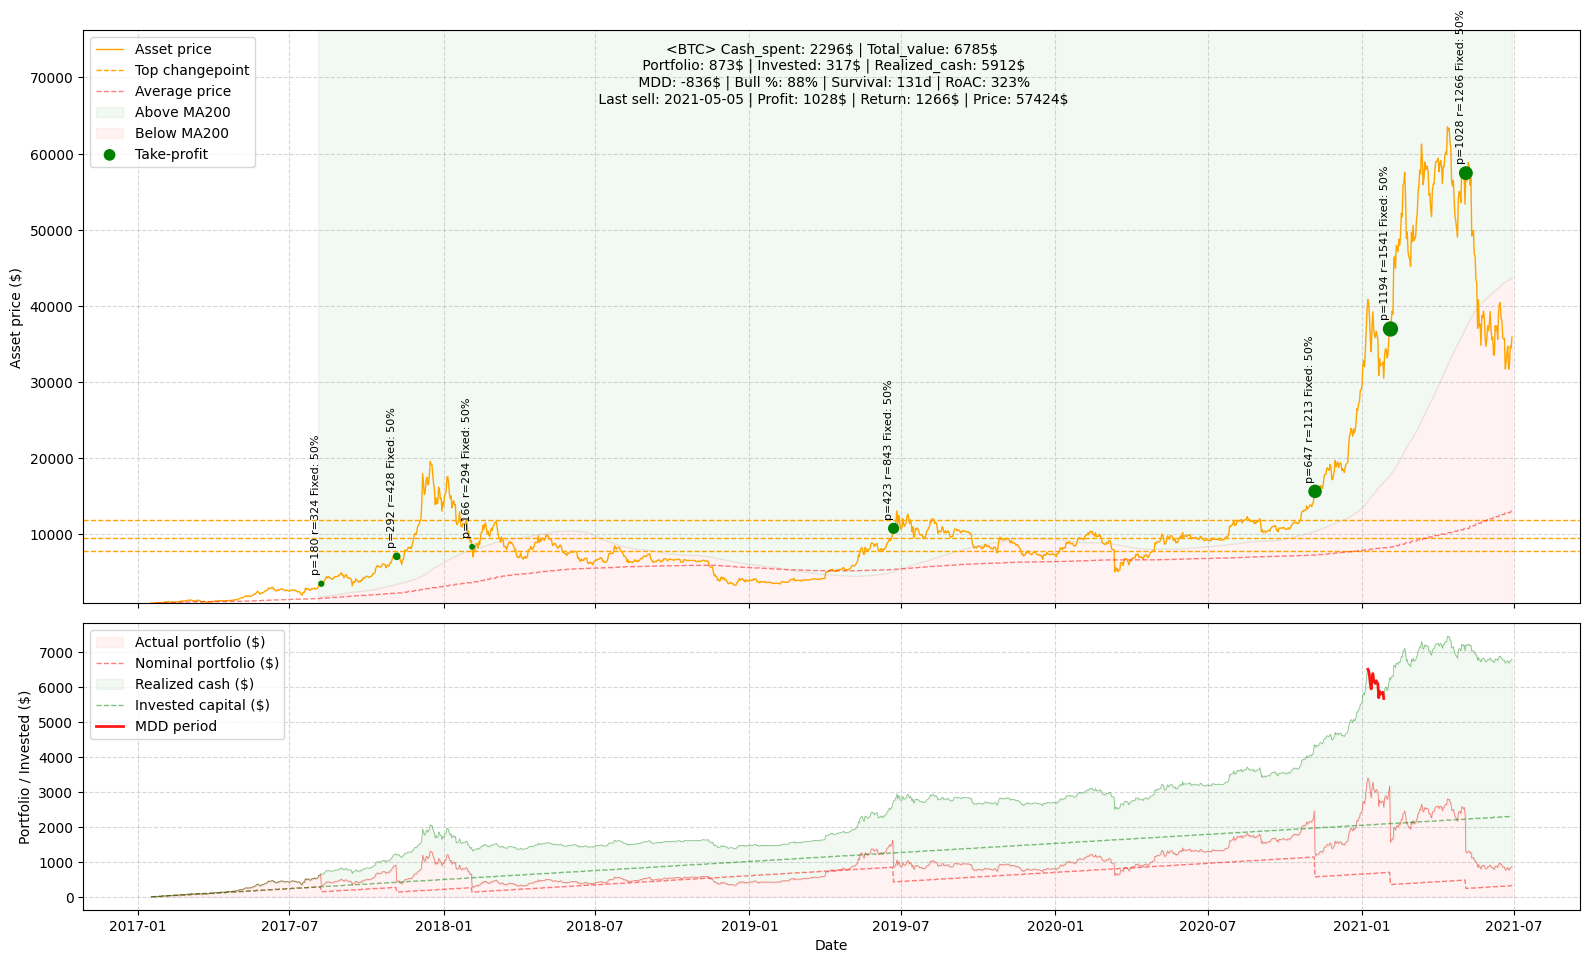

04:02:20 - cmdstanpy - INFO - Chain [1] start processing
04:02:20 - cmdstanpy - INFO - Chain [1] done processing


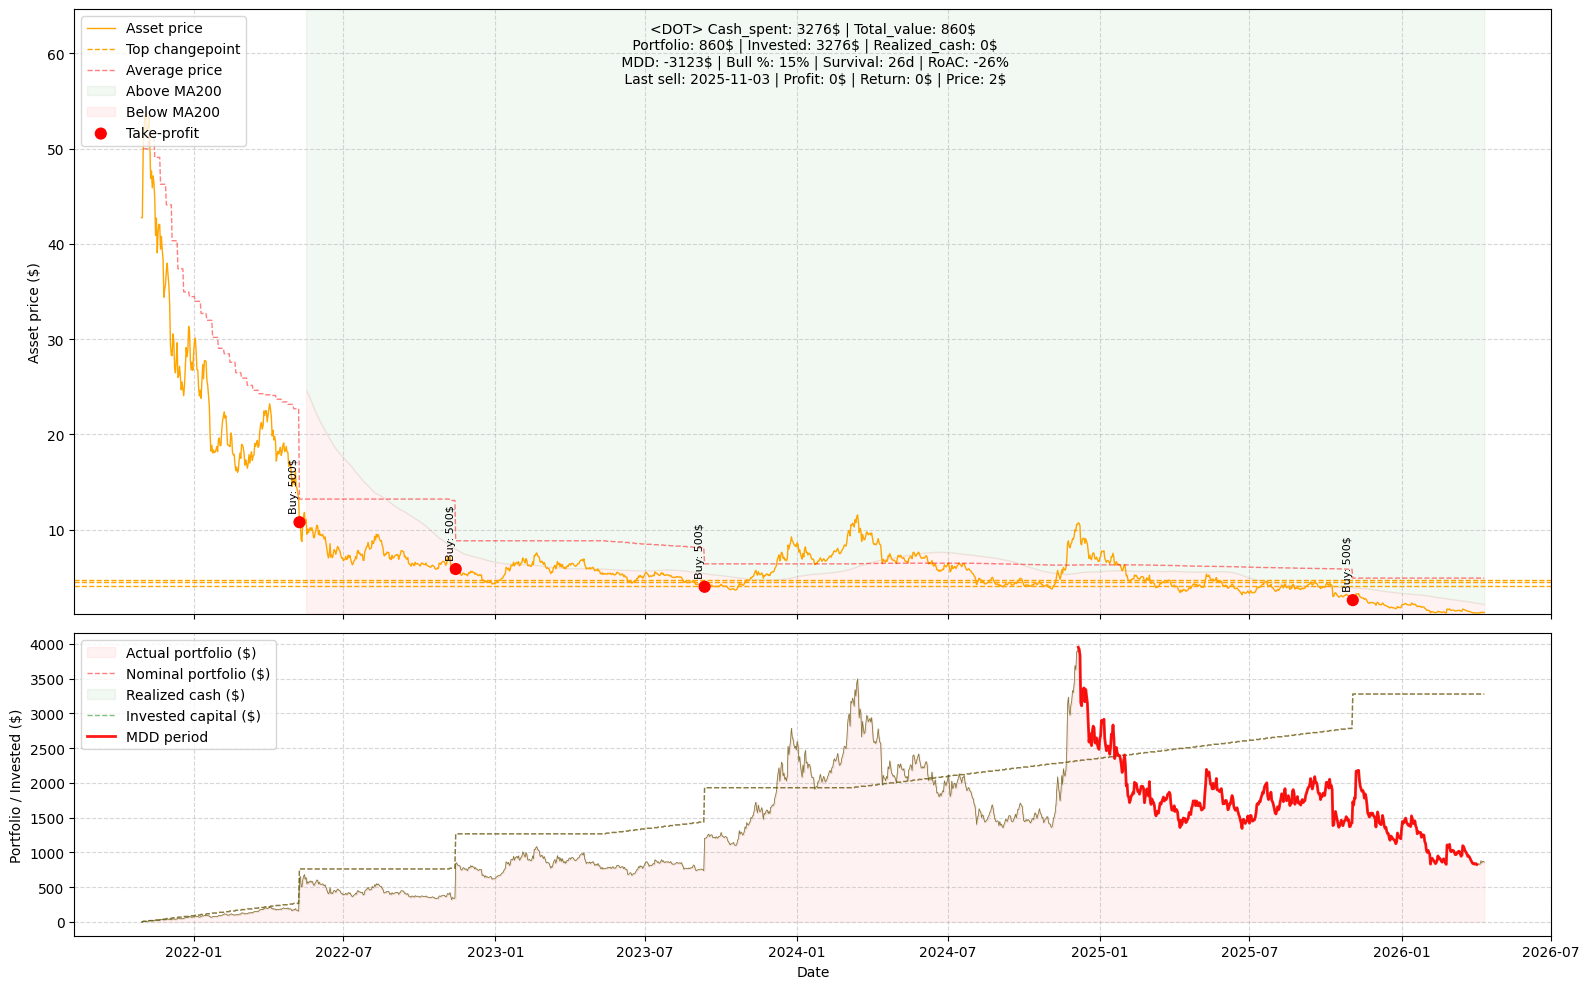

04:02:21 - cmdstanpy - INFO - Chain [1] start processing
04:02:21 - cmdstanpy - INFO - Chain [1] done processing


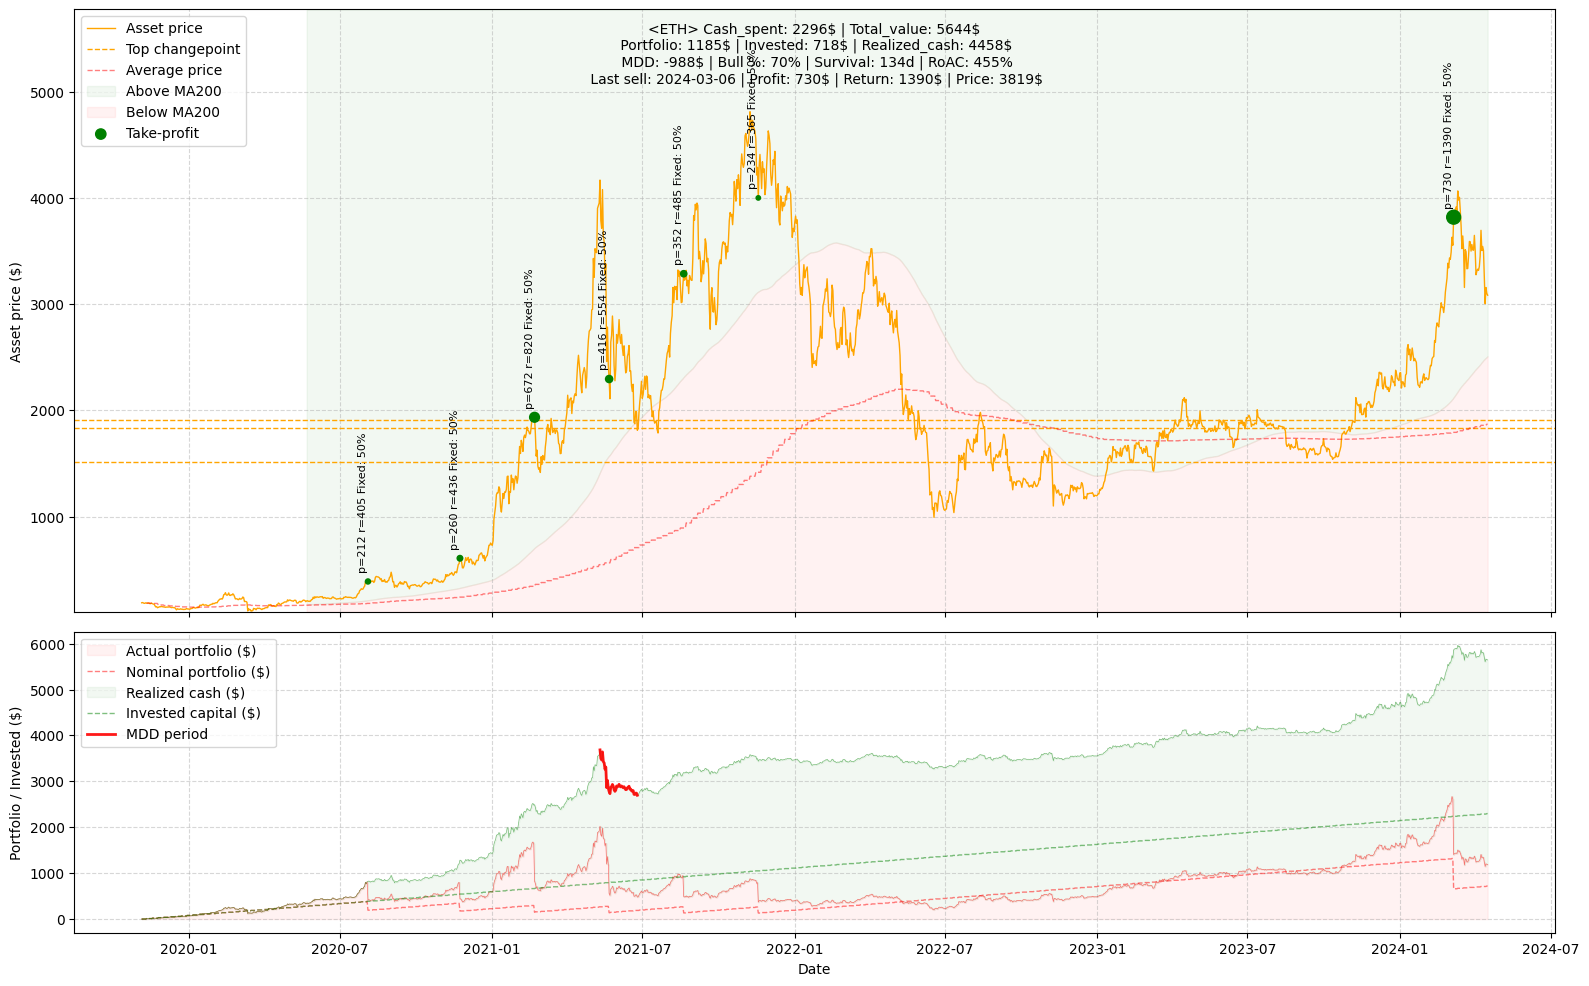

04:02:22 - cmdstanpy - INFO - Chain [1] start processing
04:02:22 - cmdstanpy - INFO - Chain [1] done processing


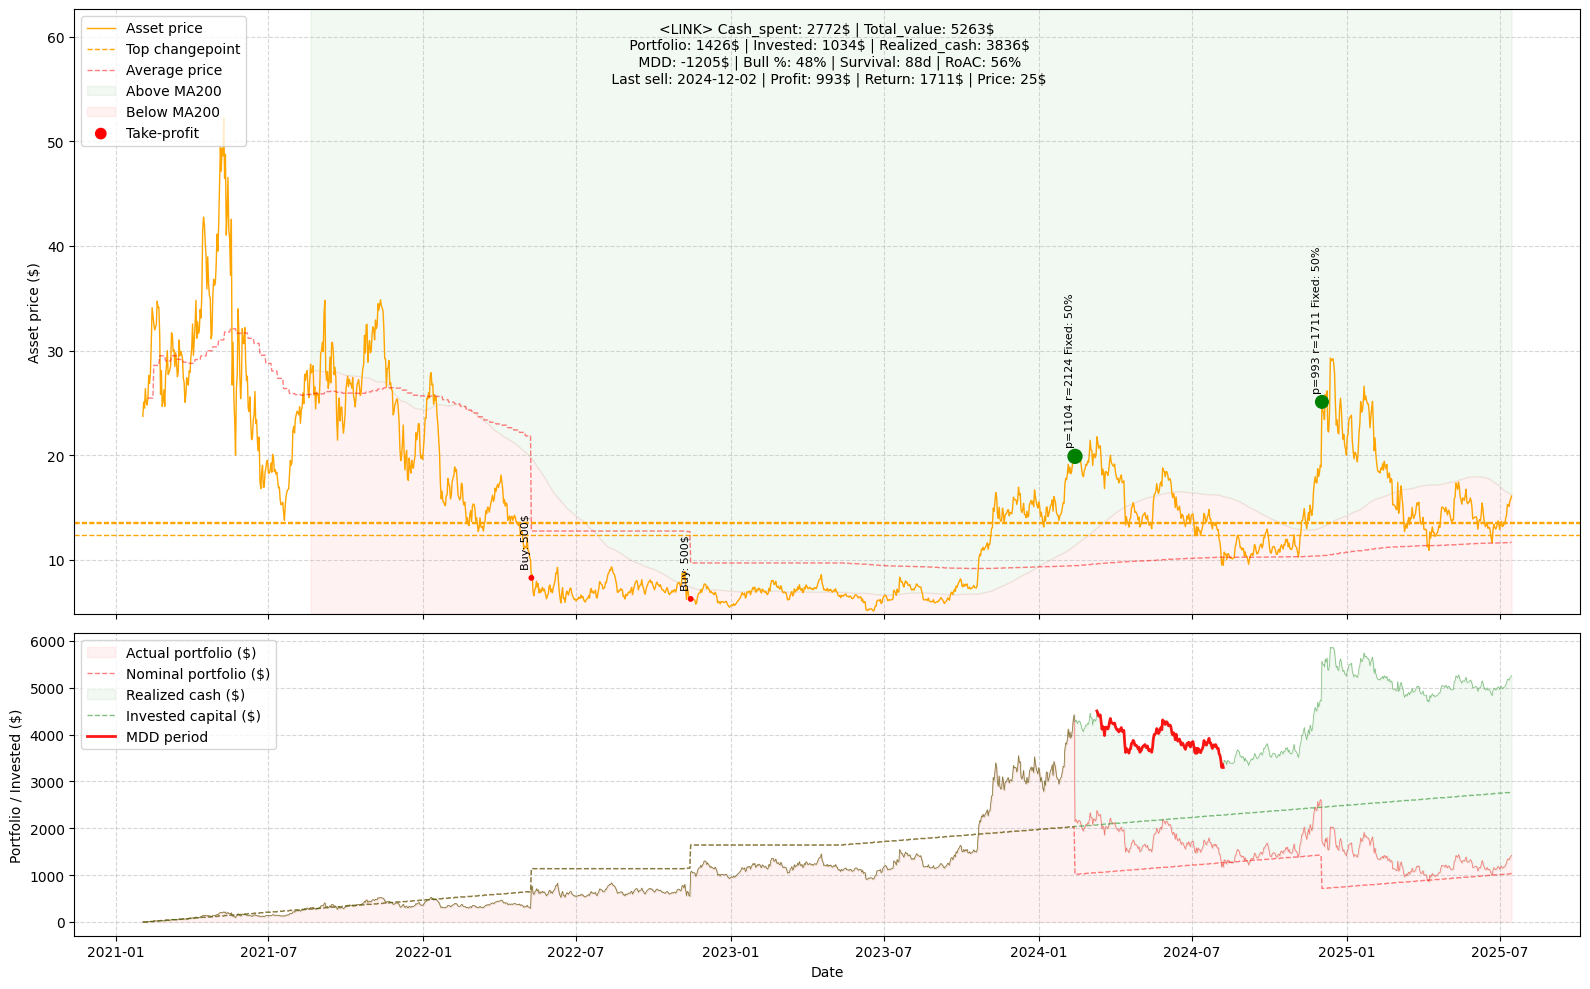

04:02:22 - cmdstanpy - INFO - Chain [1] start processing
04:02:22 - cmdstanpy - INFO - Chain [1] done processing


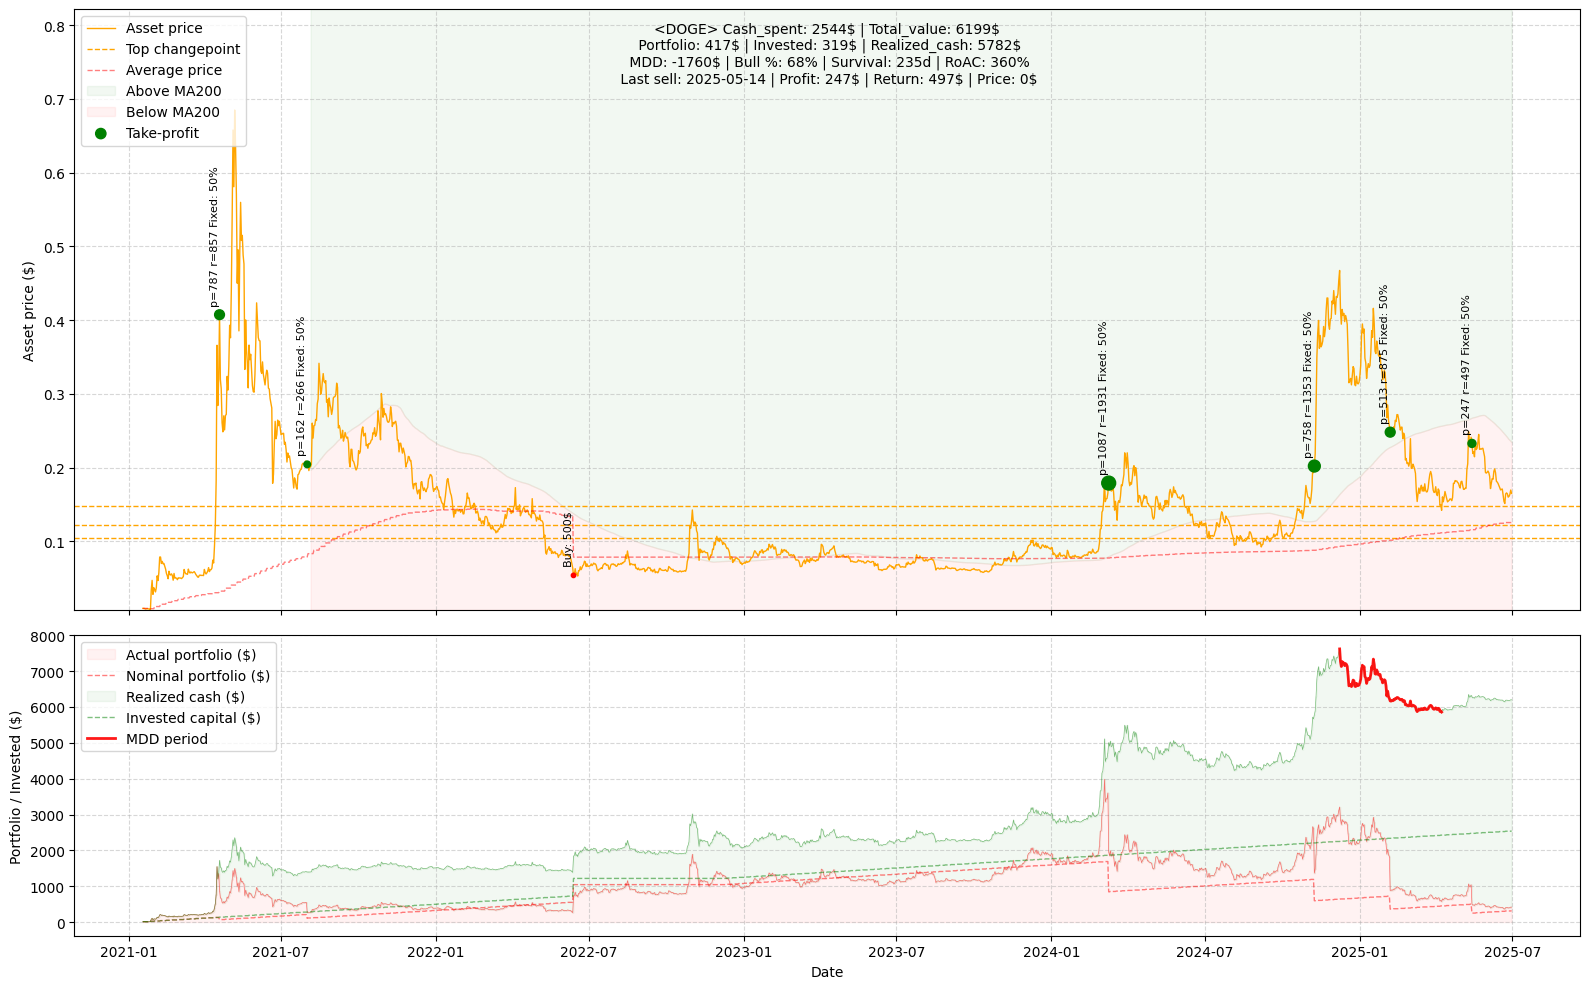

Total invested: $26330.00
Total return: $40019.00
Total value: $52227.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2021-01-18,0.009171,1079.489725,9.900000,9.9,0.0,0.0,0.000000,,9.900000,0.009171,9.900000
2021-01-19,0.009098,1079.489725,9.900000,9.9,0.0,0.0,0.000000,,9.821197,0.009171,9.821197
2021-01-20,0.009060,1079.489725,9.900000,9.9,0.0,0.0,0.000000,,9.780177,0.009171,9.780177
2021-01-21,0.008166,1079.489725,9.900000,9.9,0.0,0.0,0.000000,,8.815113,0.009171,8.815113
2021-01-22,0.008524,1079.489725,9.900000,9.9,0.0,0.0,0.000000,,9.201570,0.009171,9.201570
...,...,...,...,...,...,...,...,...,...,...,...
2025-06-26,0.159986,2466.652302,309.684375,2534.4,0.0,0.0,5782.345388,,394.629846,0.125548,6176.975234
2025-06-27,0.161068,2466.652302,309.684375,2534.4,0.0,0.0,5782.345388,,397.298771,0.125548,6179.644159
2025-06-28,0.163692,2466.652302,309.684375,2534.4,0.0,0.0,5782.345388,,403.771243,0.125548,6186.116631


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1625)

In [10]:
metrics

{'Target': 'DOGE',
 'Cash_spent': 2544,
 'Realized_cash': 5782,
 'Portfolio': 417,
 'Invested': 319,
 'Total_value': 6199,
 'Bull_history': 68,
 'Avg_price': np.float64(0.12648777385824778),
 'Num_take_profits': 7,
 'MDD': -1760,
 'MA200_survival_days': 234.99999999999997,
 'RoAC': 360}